# 1 · Reading a run file and plotting it

This notebook shows the basic building blocks of the `collide_comet` package:

1. look inside a netCDF run file,
2. load the grids and the energy-resolved electron density,
3. compute and map a quantity for one case,
4. save the figure to the repository's `Figures/` folder.

The data folder and run numbers are set once in [`run_config.py`](run_config.py).
If the run files are not found there the notebooks fall back to small **synthetic demo data**
(clearly not model results) so that every cell still runs.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

import collide_comet as cc
from collide_comet import plotting as ccp
from run_config import get_cases, make_saver

cases, DEMO = get_cases()
save = make_saver("single_run", DEMO)
cases

Using model output in E:\TestPlSimData


CaseSet('E:\\TestPlSimData', cases=['-X', '+Y', '+Z', '-Z', 'Ref'], reference='Ref')

## What is in a run file?

`cc.describe` lists the variables of a netCDF file. Shapes are given in the axis order the package
returns, e.g. the plasma density is `(nx, ny, nz, nE, n_generations)`.

In [2]:
case = cases["-X"]          # a CaseData: one photoelectron (PE) run + one solar-wind (SW) run
print(case)
cc.describe(case.pe_path);

CaseData('-X', pe=plas_dens1944473.nc, sw=plas_dens2767385.nc, asymmetric)
plas_dens1944473.nc
  'X Boundaries'               (81,)
  'Y Boundaries'               (61,)
  'Z Boundaries'               (61,)
  'Energy Boundaries'          (51,)
  'dT Boundaries'              (81,)
  'dT Count'                   (80,)
  'Plasma Density'             (80, 60, 60, 50, 2)
  'Bulk Velocity'              (3, 80, 60, 60, 2)
  'Cold Elec Bulk Velocity'    (3, 80, 60, 60, 2)
  'Square Velocity'            (3, 80, 60, 60, 2)
  'Particle Count with E'      (80, 60, 60, 50, 2)
  'Particle Count'             (80, 60, 60, 2)
  'Final Time Step'            (6001, 5)
  'Terminating Pl. Time'       (141, 5)
  'Number Pls'                 (5,)
  'Cell Weight'                (80, 60, 60)
  'Pls per Cell'               (80, 60, 60)
  'Photoel Eng Dist'           (50,)
  'Sec Elec Weight'            (80, 60, 60)
  'El Impact Ioni Rate'        (80, 60, 60)
  'elDepthGrid'                (51,)
  'elDepthRadGrid

## Low-level readers

These mirror the MATLAB loaders (`loadRunData`, `loadOutgassingProperties`, `load_velocity_arrays`, …).
Arrays are indexed `[ix, iy, iz, ...]` – there is no `permute` step as in MATLAB.

In [3]:
grids, plas_dens_E = cc.load_run_data(case.pe_path)
outgassing = cc.load_outgassing(case.sw_path)
xs = cc.load_cross_sections()        # Coll_XS.nc bundled with the package

print("cells           :", grids.shape, " energy bins:", grids.n_energy)
print("x range [km]    :", grids.x[0], "to", grids.x[-1])
print("energy grid [eV]:", grids.energy[0], "to", grids.energy[-1])
print("plas_dens_E     :", plas_dens_E.shape, plas_dens_E.dtype)
print(outgassing)
print("cross sections  :", xs.xs.shape, "(energies, processes)")

cells           : (80, 60, 60)  energy bins: 50
x range [km]    : -400.0 to 400.0
energy grid [eV]: 0.0 to 30000.00000000007
plas_dens_E     : (80, 60, 60, 50, 2) float64
Outgassing(q_spherical=3.74999986458186e+26, q_dayside=2.7500000236716578e+26, q_uniform=1.0000000253776429e+26, q_vec=array([-1.,  0.,  0.]))
cross sections  : (103, 12) (energies, processes)


## Derived quantities

`collide_comet.physics` holds the calculations (`calculatePlasmaDensities`, `calcEIoniFreq`,
`calculateColdeProduction`, …). Generations are 0-based: MATLAB `inc_gens = [1, 2]` is `gens=(0, 1)`.

saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\pe_run_density_and_ionisation_XZ.png


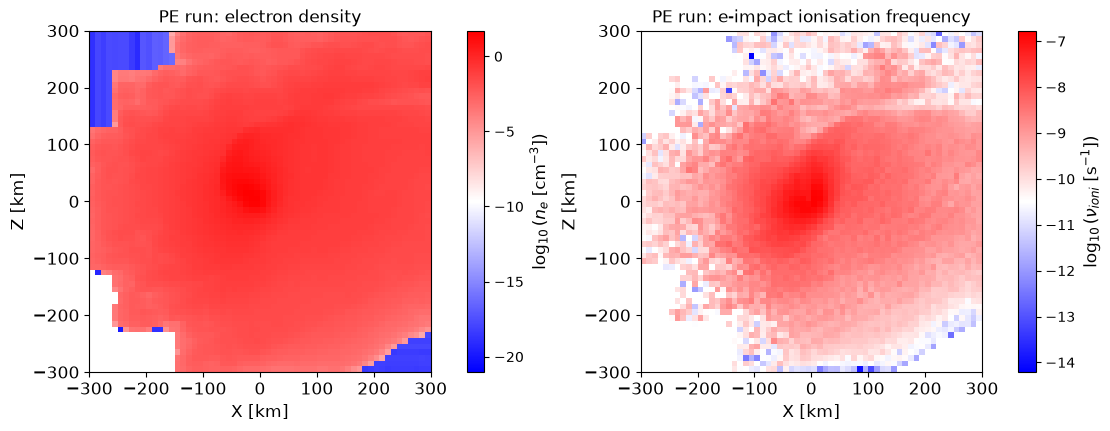

In [4]:
n_e, n_cold = cc.physics.plasma_densities(grids, plas_dens_E, gens=(0, 1), min_energy=0, max_energy=1)
nu_ioni = cc.physics.eii_frequency(plas_dens_E, grids.energy, xs)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
ccp.plot_slice(n_e, grids, view="XZ", log=True, label=r"$n_e$ [cm$^{-3}$]", ax=axes[0])
ccp.plot_slice(nu_ioni, grids, view="XZ", log=True, label=r"$\nu_{ioni}$ [s$^{-1}$]", ax=axes[1])
axes[0].set_title("PE run: electron density")
axes[1].set_title("PE run: e-impact ionisation frequency")
save(fig, "pe_run_density_and_ionisation_XZ");

## Working with a case (PE + SW combined)

A `CaseData` adds the two runs, applies the right outgassing model and caches what it computes.
`cc.list_quantities()` shows every named quantity that can be mapped.

In [5]:
cc.list_quantities();

total_density                All electrons (PE + SW runs, both generations)
cold_density                 Electrons below 1 eV (PE + SW runs, both generations)
pe_density                   Primary photoelectrons
sw_density                   Primary solar-wind electrons
sw_warm_density              Primary solar-wind electrons between 3 and 350 eV
sw_secondary_cold_density    Cold secondaries produced by solar-wind electrons
secondary_density            Secondary electrons (PE + SW runs)
neutral_density              Neutral water density of the coma model
eii_frequency                Electron-impact ionisation frequency
eii_production               Electron-impact ionisation production rate
cold_electron_production     Production rate of electrons below 1 eV
temperature                  Temperature of the combined electron population
sw_temperature               Temperature of the primary solar-wind electrons


saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\total_density_case-X_YZ.png
saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\total_density_case-X_XZ.png
saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\total_density_case-X_XY.png


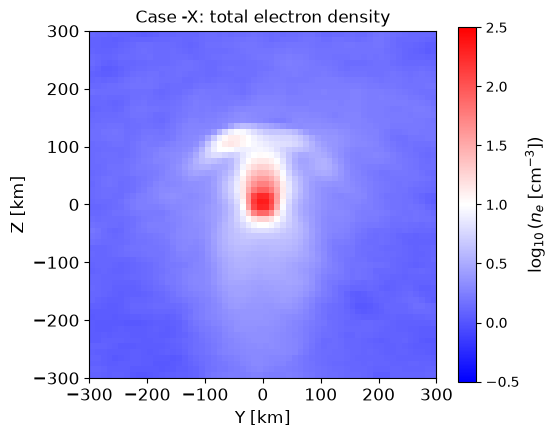

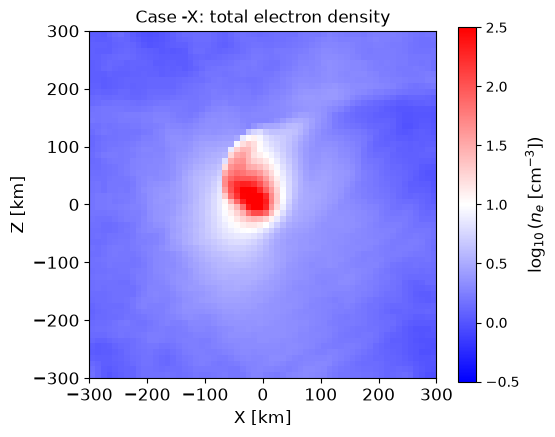

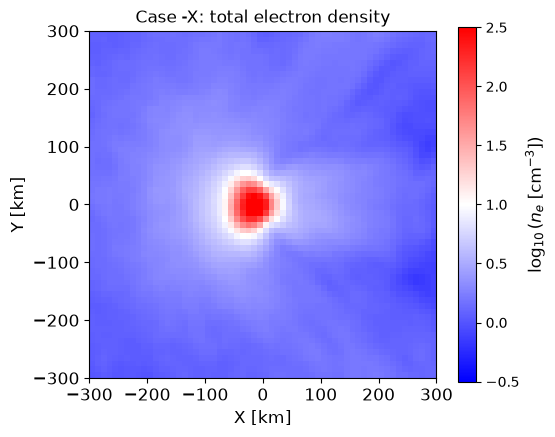

In [6]:
for view in ["YZ", "XZ", "XY"]:
    fig, ax, mesh, cbar = ccp.plot_quantity(case, "total_density", view=view)
    ax.set_title(f"Case {case.name}: total electron density")
    save(fig, f"total_density_case{case.name}_{view}")

saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\overview_case-X_XZ.png


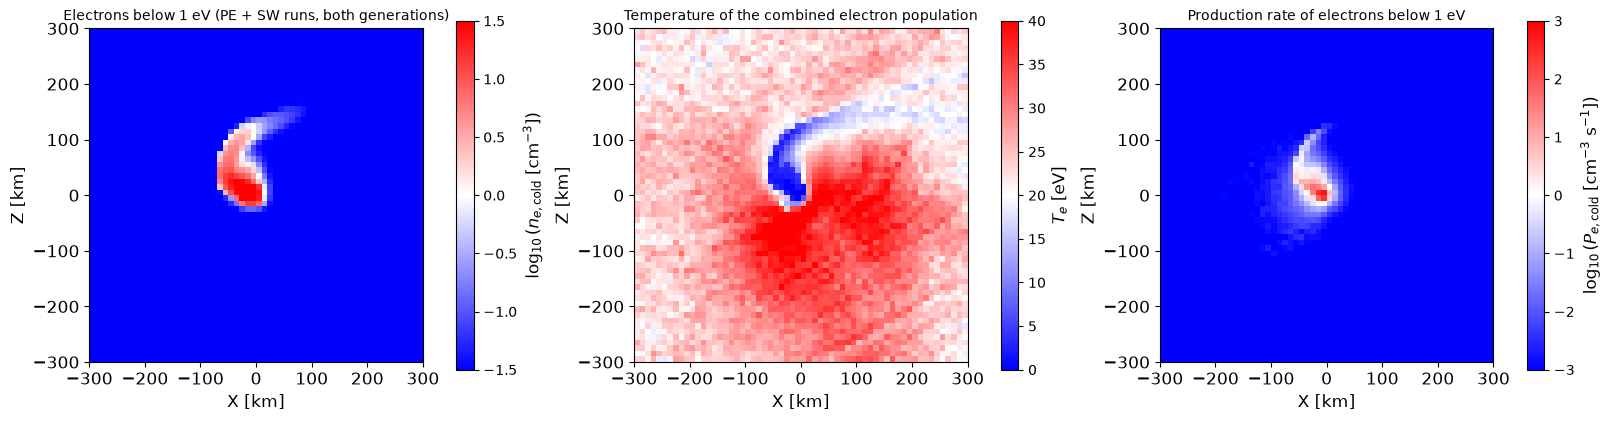

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)
for ax, quantity in zip(axes, ["cold_density", "temperature", "cold_electron_production"]):
    ccp.plot_quantity(case, quantity, view="XZ", ax=ax)
    ax.set_title(cc.QUANTITIES[quantity].description, fontsize=10)
save(fig, f"overview_case{case.name}_XZ");

## Energy distribution along a line

`plot_edf` is the port of `make_edf_plot`: $\log_{10} f(E)$ along a line through the nucleus.

saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\sw_edf_case-X_X.png


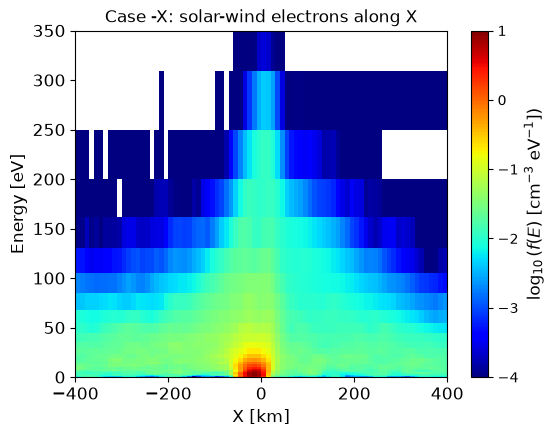

In [8]:
f_sw = case.plasma_density_E("sw")[..., 0]      # primary solar-wind electrons
fig, ax, mesh, cbar = ccp.plot_edf(f_sw, case.grids, axis="X")
ax.set_ylim(0, 350)
ax.set_title(f"Case {case.name}: solar-wind electrons along X")
save(fig, f"sw_edf_case{case.name}_X");

## Time-step histogram

The `dT` histogram from the top of `asymmetricPlots.m`.

saved c:\Users\pete4\GitHub\collide_comet\Figures\single_run\timestep_histogram_case-X.png


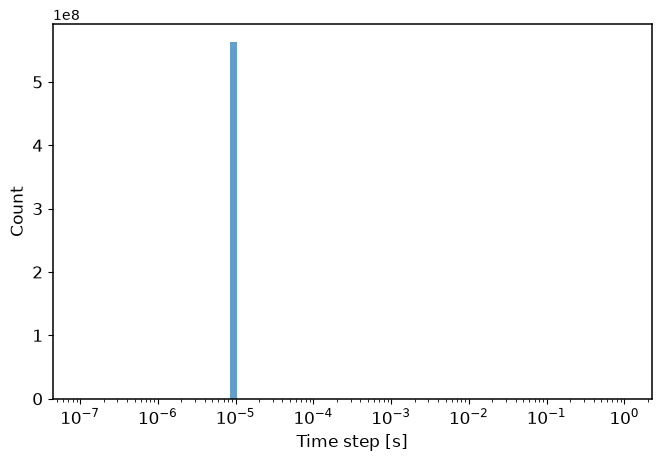

In [9]:
fig, ax, _ = ccp.timestep_histogram(case.pe_path)
save(fig, f"timestep_histogram_case{case.name}");